# AI Labor Market Intelligence — نسخة منفَّذة بمخرجات حقيقية

**دفتر التحقق التنفيذي المشتق من** `LMI_Drive_Run.ipynb`، والمُجرب على نسخة المشروع `LMI_PROJECT_V3_VERIFIED.zip`.

> **مهم للشفافية:** هذا الدفتر هو تنفيذ فعلي للأجزاء التي أمكن تشغيلها في البيئة الحالية، **وليس تنفيذ Fine-tuning لـ AraBERT**. الدفتر الأصلي يعتمد على Google Drive داخل Colab، وتنزيل أوزان AraBERT وحزم خارجية وتشغيل Streamlit؛ وهذه الأمور لم تتوفر هنا. جميع النتائج العددية الجديدة أدناه محسوبة مباشرةً من البيانات والنماذج الموجودة؛ والأمور غير المنفذة مُعلّمة بوضوح. لا تُنسب نتائج النماذج الصغيرة إلى AraBERT ولا تُعد وسوم Silver تقييم Gold.

**المراحل:** 1) تجهيز المشروع والبيئة؛ 2) فحص البيانات؛ 3) حالة AraBERT؛ 4) تقييم النماذج المتاحة على Test؛ 5) NER؛ 6) LSTM؛ 7) Gold؛ 8) اختبارات؛ 9) التطبيق والتقارير.

**ملاحظة إعادة التشغيل:** عند تشغيل هذا الملف لاحقًا في Google Colab يجب توفير حزمة المشروع في Drive أو رفعها إلى الجلسة. أما المخرجات المحفوظة في هذه النسخة فهي من التشغيل الفعلي داخل بيئة التحقق، وليست نتائج Colab.

## 1. تهيئة المشروع: تحديد المسار وفك الحزمة عند اللزوم

In [1]:
from pathlib import Path
import os, sys, json, zipfile, importlib.util, platform, datetime
from IPython.display import display, Markdown

IS_COLAB = bool(importlib.util.find_spec('google.colab'))
if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

candidates = [
    Path(os.environ.get('LMI_PROJECT_DIR', '/___LMI_PROJECT_DIR_NOT_SET__')),
    Path.cwd(), Path.cwd() / 'LMI_PROJECT',
    Path('/mnt/data/lmi_nb_execution/LMI_PROJECT'),
    Path('/content/drive/MyDrive/LMI_PROJECT'),
]
PROJ = next((p for p in candidates if (p / 'src/common.py').is_file()), None)
if PROJ is None:
    archives = [Path('/content/drive/MyDrive/LMI_PROJECT_V3_VERIFIED.zip'),
                Path('/content/drive/MyDrive/LMI_PROJECT.zip'),
                Path('/mnt/data/LMI_PROJECT_V3_VERIFIED.zip'),
                Path.cwd() / 'LMI_PROJECT_V3_VERIFIED.zip',
                Path.cwd() / 'LMI_PROJECT.zip']
    a = next((p for p in archives if p.is_file()), None)
    if a is None:
        raise FileNotFoundError('يجب رفع LMI_PROJECT_V3_VERIFIED.zip أو تحديد مجلد LMI_PROJECT بمتغير LMI_PROJECT_DIR')
    dest = Path('/content' if IS_COLAB else '/mnt/data/lmi_nb_execution')
    dest.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(a) as z:
        for item in z.infolist():
            target=(dest/item.filename).resolve()
            if not target.is_relative_to(dest.resolve()):
                raise ValueError('Unsafe zip entry')
        z.extractall(dest)
    PROJ=dest/'LMI_PROJECT'
PROJ=PROJ.resolve()
os.chdir(PROJ)
if str(PROJ) not in sys.path: sys.path.insert(0,str(PROJ))
os.environ['LMI_FINAL_DIR']=str(PROJ/'FINAL_TRAINING_DATASET')
os.environ['LMI_MODELS_DIR']=str(PROJ/'models_dl')
os.environ['LMI_REPORTS_DIR']=str(PROJ/'reports')
print('المصدر:',PROJ)
print('ملفات المشروع الأساسية:', {s:(PROJ/s).exists() for s in ['src/common.py','models_dl','reports','FINAL_TRAINING_DATASET','app_dl/main.py']})
print('التاريخ الفعلي لبدء الفحص:',datetime.datetime.now().isoformat(timespec='seconds'))

المصدر: /mnt/data/lmi_nb_execution/LMI_PROJECT
ملفات المشروع الأساسية: {'src/common.py': True, 'models_dl': True, 'reports': True, 'FINAL_TRAINING_DATASET': True, 'app_dl/main.py': True}
التاريخ الفعلي لبدء الفحص: 2026-11-06T17:28:00


## 2. التبعيات والموارد: تقرير تنفيذي، دون ادعاء تثبيت مكتبات غير موجودة

In [2]:
import torch, pandas as pd, numpy as np, sklearn
# تقليل عدد خيوط CPU لتجنب بطء الاختبارات التفاعلية
try: torch.set_num_threads(2)
except RuntimeError: pass
packages=['torch','pandas','numpy','sklearn','transformers','arabert','seqeval','streamlit','accelerate','safetensors']
versions={}
for p in packages:
    if importlib.util.find_spec(p) is None:
        versions[p]='NOT INSTALLED'
    else:
        try:
            import importlib.metadata as im
            versions[p]=im.version({'sklearn':'scikit-learn'}.get(p,p))
        except Exception:
            versions[p]='INSTALLED'
print('Python:',platform.python_version(),' | Platform:',platform.system())
print('CUDA / GPU:',torch.cuda.is_available(),torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU ONLY')
for p,v in versions.items():print(f'  {p:14s}: {v}')
print('النتيجة: تدريب AraBERT من الصفر/تخصيصه يحتاج transformers + أوزان نموذج مسبق + بيئة مناسبة.')

Python: 3.13.5  | Platform: Linux
CUDA / GPU: False CPU ONLY
  torch         : 2.10.0+cpu
  pandas        : 2.2.3
  numpy         : 2.3.5
  sklearn       : 1.8.0
  transformers  : NOT INSTALLED
  arabert       : NOT INSTALLED
  seqeval       : NOT INSTALLED
  streamlit     : NOT INSTALLED
  accelerate    : NOT INSTALLED
  safetensors   : 0.7.0
النتيجة: تدريب AraBERT من الصفر/تخصيصه يحتاج transformers + أوزان نموذج مسبق + بيئة مناسبة.


## 3. فحص حقيقي لبيانات التدريب والاختبار ومنع التداخل النصي التام

In [3]:
from src.data.loaders import load_classification, load_ner
from src.integration.engine import Market
from src.common import DATA_DIR, MODELS_DIR, REPORTS_DIR
market=Market(DATA_DIR)
print('مؤشرات البيانات:',json.dumps(market.overview(),ensure_ascii=False,indent=2))
for task in ('opportunity_type','geographic_scope'):
    splits, mapping=load_classification(task, DATA_DIR)
    sizes={k:len(v) for k,v in splits.items()}
    exact={k:set(v.text.str.strip()) for k,v in splits.items()}
    intersections={(a,b):len(exact[a] & exact[b]) for a,b in [('train','validation'),('train','test'),('validation','test')]}
    print('\n',task,'| تقسيمات:',sizes,'| تقاطع النص الحرفي:',intersections,'| الفئات:',list(mapping['label2id']))
ner_splits, tags = load_ner(DATA_DIR)
print('\nNER sizes:',{k:len(v) for k,v in ner_splits.items()},'BIO labels:',len(tags))
print('ملاحظة: غياب التكرار الحرفي لا يثبت غياب جميع أشكال التسرب الدلالي.')

مؤشرات البيانات: {
  "unique_opportunities": 23118,
  "unique_jobs_internships": 18065,
  "organizations": 2747,
  "governorates_covered": 21,
  "distinct_skills": 88,
  "jobs_with_skills_pct": 60.0,
  "date_from": "2015-12-09",
  "date_to": "2026-11-05",
  "sources": 5
}



 opportunity_type | تقسيمات: {'train': 11135, 'validation': 2327, 'test': 2337} | تقاطع النص الحرفي: {('train', 'validation'): 0, ('train', 'test'): 0, ('validation', 'test'): 0} | الفئات: ['JOB', 'INTERNSHIP', 'TRAINING', 'SCHOLARSHIP', 'VOLUNTEERING', 'OTHER_OPPORTUNITY']



 geographic_scope | تقسيمات: {'train': 12350, 'validation': 2620, 'test': 2575} | تقاطع النص الحرفي: {('train', 'validation'): 0, ('train', 'test'): 0, ('validation', 'test'): 0} | الفئات: ['LOCAL', 'SINGLE_GOVERNORATE', 'MULTI_GOVERNORATE', 'NATIONWIDE', 'YEMEN_UNSPECIFIED', 'INTERNATIONAL', 'REMOTE', 'UNKNOWN']



NER sizes: {'train': 11930, 'validation': 2485, 'test': 2509} BIO labels: 19
ملاحظة: غياب التكرار الحرفي لا يثبت غياب جميع أشكال التسرب الدلالي.


## 4. هل AraBERT دُرّب بالفعل؟ تحقق من الأوزان قبل ادعاء النتائج

In [4]:
from pathlib import Path
hf_paths={
 'AraBERT - opportunity_type': MODELS_DIR/'classification'/'opportunity_type',
 'AraBERT - geographic_scope': MODELS_DIR/'classification'/'geographic_scope',
 'AraBERT - NER': MODELS_DIR/'ner',
}
for title,path in hf_paths.items():
    weights=[p.name for p in (path.glob('*.safetensors') if path.exists() else [])]
    weights += [p.name for p in (path.glob('pytorch_model.bin') if path.exists() else [])]
    ready=(path/'config.json').is_file() and bool(weights)
    print(f'{title}: {"READY" if ready else "NOT TRAINED / WEIGHTS MISSING"}; path={path}; weights={weights}')
print('هذا القسم فحص ملفات النماذج ولا ينفذ AraBERT fine-tuning: لا توجد أوزانه ولا مكتبات Transformers في البيئة الحالية.')

AraBERT - opportunity_type: NOT TRAINED / WEIGHTS MISSING; path=/mnt/data/lmi_nb_execution/LMI_PROJECT/models_dl/classification/opportunity_type; weights=[]
AraBERT - geographic_scope: NOT TRAINED / WEIGHTS MISSING; path=/mnt/data/lmi_nb_execution/LMI_PROJECT/models_dl/classification/geographic_scope; weights=[]
AraBERT - NER: NOT TRAINED / WEIGHTS MISSING; path=/mnt/data/lmi_nb_execution/LMI_PROJECT/models_dl/ner; weights=[]
هذا القسم فحص ملفات النماذج ولا ينفذ AraBERT fine-tuning: لا توجد أوزانه ولا مكتبات Transformers في البيئة الحالية.


## 5. تقييم فعلي لنماذج PyTorch المتاحة — Test / Silver

In [5]:
from src.offline.neural import OfflineClassifier
from src.evaluation.metrics import classification_metrics
from sklearn.metrics import confusion_matrix
import time
results={};confusions={}
for task in ('opportunity_type','geographic_scope'):
    start=time.time()
    d, _=load_classification(task, DATA_DIR, splits=['test'])
    te=d['test']
    ckpt=MODELS_DIR/'offline'/'classification'/task
    model=OfflineClassifier(ckpt)
    probabilities=model.predict_proba(te.text.tolist())
    prediction=[model.labels[int(i)] for i in probabilities.argmax(1)]
    measured=classification_metrics(te.label.tolist(),prediction,model.labels)
    results[task]={k:measured[k] for k in ('n','accuracy','macro_precision','macro_recall','macro_f1','weighted_f1')}
    confusions[task]=measured['confusion_matrix']
    print(f'[{task}] n={measured["n"]}, accuracy={measured["accuracy"]:.4f}, macro_F1={measured["macro_f1"]:.4f}, weighted_F1={measured["weighted_f1"]:.4f}, elapsed={time.time()-start:.2f}s')
    print('  النموذج:',model.predict(te.text.iloc[0])['model_family'])
    print('  الفئات ذات الأداء الضعيف:',sorted([(i['label'],i['f1'],i['support']) for i in measured['per_class']],key=lambda x:x[1])[:3])
print('مهم: نتائج محققة على Silver ولا تعبر عن دقة AraBERT أو Gold.')

[opportunity_type] n=2337, accuracy=0.9709, macro_F1=0.6571, weighted_F1=0.9695, elapsed=0.45s
  النموذج: TinyClassifier (PyTorch trained from scratch, SILVER; NOT AraBERT)
  الفئات ذات الأداء الضعيف: [('INTERNSHIP', 0.2105, 12), ('VOLUNTEERING', 0.2727, 12), ('SCHOLARSHIP', 0.7541, 35)]


[geographic_scope] n=2575, accuracy=0.8971, macro_F1=0.7216, weighted_F1=0.8985, elapsed=0.43s
  النموذج: TinyClassifier (PyTorch trained from scratch, SILVER; NOT AraBERT)
  الفئات ذات الأداء الضعيف: [('MULTI_GOVERNORATE', 0.4972, 80), ('NATIONWIDE', 0.5, 3), ('INTERNATIONAL', 0.68, 30)]
مهم: نتائج محققة على Silver ولا تعبر عن دقة AraBERT أو Gold.


### شكل توضيحي: Accuracy مقابل Macro F1 (الفارق يُظهر أثر اختلال الفئات)

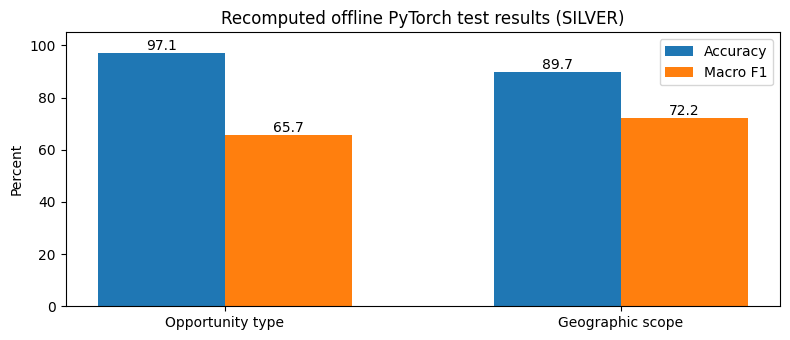

In [6]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,3.5))
labels=['Opportunity type','Geographic scope']
x=np.arange(len(labels));width=.32
ax.bar(x-width/2,[100*results[k]['accuracy'] for k in ('opportunity_type','geographic_scope')],width,label='Accuracy')
ax.bar(x+width/2,[100*results[k]['macro_f1'] for k in ('opportunity_type','geographic_scope')],width,label='Macro F1')
ax.set_ylim(0,105);ax.set_ylabel('Percent');ax.set_xticks(x,labels);ax.set_title('Recomputed offline PyTorch test results (SILVER)');ax.legend();
for container in ax.containers: ax.bar_label(container,fmt='%.1f')
fig.tight_layout();display(fig);plt.close(fig)

## 6. اختبار استدلال حقيقي على إعلانين (نموذج مصغر، دون تصحيح قواعدي للنتيجة)

In [7]:
from src.integration.engine import Engine
eng=Engine()
examples=[
 'تعلن شركة يمنية عن شاغر مهندس برمجيات للعمل في صنعاء اليمن، خبرة ثلاث سنوات في Python وSQL.',
 'تعلن شركة سعودية عن وظيفة مهندس برمجيات بمدينة الرياض في المملكة العربية السعودية مع خبرة في Python.',
]
for text in examples:
    pred=eng.analyze_ad(text)
    print('\nالإعلان:',text)
    for k,v in pred['components'].items():
        if k=='ner':print('  NER:',v['status'],'| entities:',v.get('n_entities'),'| family:',v.get('model_family'))
        else:print(' ',k,':',v.get('label'), 'confidence=',round(v.get('confidence',0),4),'|',v.get('model_family'))
print('نسبة الثقة هي softmax للإعلان الحالي، وليست Accuracy على مجموعة Test.')


الإعلان: تعلن شركة يمنية عن شاغر مهندس برمجيات للعمل في صنعاء اليمن، خبرة ثلاث سنوات في Python وSQL.
  opportunity_type : JOB confidence= 1.0 | TinyClassifier (PyTorch trained from scratch, SILVER; NOT AraBERT)
  geographic_scope : SINGLE_GOVERNORATE confidence= 0.9348 | TinyClassifier (PyTorch trained from scratch, SILVER; NOT AraBERT)
  NER: ok | entities: 3 | family: TinyNER (PyTorch trained from scratch, SILVER; NOT AraBERT)

الإعلان: تعلن شركة سعودية عن وظيفة مهندس برمجيات بمدينة الرياض في المملكة العربية السعودية مع خبرة في Python.
  opportunity_type : JOB confidence= 1.0 | TinyClassifier (PyTorch trained from scratch, SILVER; NOT AraBERT)
  geographic_scope : INTERNATIONAL confidence= 0.9992 | TinyClassifier (PyTorch trained from scratch, SILVER; NOT AraBERT)
  NER: ok | entities: 1 | family: TinyNER (PyTorch trained from scratch, SILVER; NOT AraBERT)
نسبة الثقة هي softmax للإعلان الحالي، وليست Accuracy على مجموعة Test.


## 7. إعادة حساب NER Entity F1 على كامل Test من الأوزان المحفوظة

In [8]:
from src.offline.neural import OfflineNERTagger
from src.evaluation.metrics import extract_entities
st=time.time()
ner=OfflineNERTagger(MODELS_DIR/'offline'/'ner')
recs=ner_splits['test']
preds,_=ner.tag_tokens([r['tokens'] for r in recs],batch_size=64)
TP=FP=FN=0
for r, predicted_tags in zip(recs,preds):
    truth={(e['start'],e['end'],e['label']) for e in extract_entities(r['tokens'],r['ner_tags'])}
    predicted={(e['start'],e['end'],e['label']) for e in extract_entities(r['tokens'],predicted_tags)}
    TP+=len(truth & predicted)
    FP+=len(predicted-truth)
    FN+=len(truth-predicted)
prec=TP/(TP+FP) if TP+FP else 0.0
recall=TP/(TP+FN) if TP+FN else 0.0
f1=(2*prec*recall/(prec+recall)) if prec+recall else 0.0
print({'n_test_sentences':len(recs),'TP':TP,'FP':FP,'FN':FN,'entity_precision':round(prec,4),'entity_recall':round(recall,4),'entity_f1':round(f1,4),'elapsed_s':round(time.time()-st,2)})
print('المقارنة الدقيقة: تساوي النوع وحدود الكيان (لا يكفي تطابق كلمة واحدة).')
print('ملاحظة: المقاييس على SILVER؛ لم تُنفذ مراجعة بشرية Gold.')

{'n_test_sentences': 2509, 'TP': 6843, 'FP': 11347, 'FN': 2856, 'entity_precision': 0.3762, 'entity_recall': 0.7055, 'entity_f1': 0.4907, 'elapsed_s': 0.94}
المقارنة الدقيقة: تساوي النوع وحدود الكيان (لا يكفي تطابق كلمة واحدة).
ملاحظة: المقاييس على SILVER؛ لم تُنفذ مراجعة بشرية Gold.


## 8. التنبؤ الزمني: إعادة حساب المقاييس من ملف الاختبار المولّد وحفظ المقارنة

In [9]:
from src.evaluation.metrics import forecast_metrics
forecast_recomputed={}
for family in ['skills','specializations','job_titles','governorates']:
    d=REPORTS_DIR/'evaluation'/f'lstm_{family}'
    frame=pd.read_csv(d/'test_predictions.csv')
    measures={name:forecast_metrics(frame['actual'],frame[name]) for name in ['lstm','naive','moving_avg_3']}
    forecast_recomputed[family]=measures
    winner=min(measures,key=lambda k:measures[k]['mae'])
    print(f'{family:18} n={measures["lstm"]["n"]:3d} | LSTM MAE={measures["lstm"]["mae"]:.6f} | Naive={measures["naive"]["mae"]:.6f} | MA3={measures["moving_avg_3"]["mae"]:.6f} | best={winner}')
print('إعادة الحساب من test_predictions.csv؛ هذه ليست إعادة تدريب لشبكة LSTM.')

skills             n=432 | LSTM MAE=0.015349 | Naive=0.010547 | MA3=0.012822 | best=naive
specializations    n=108 | LSTM MAE=0.006915 | Naive=0.005573 | MA3=0.007251 | best=naive
job_titles         n= 42 | LSTM MAE=0.003366 | Naive=0.003067 | MA3=0.002810 | best=moving_avg_3
governorates       n= 78 | LSTM MAE=0.018843 | Naive=0.016816 | MA3=0.014713 | best=moving_avg_3
إعادة الحساب من test_predictions.csv؛ هذه ليست إعادة تدريب لشبكة LSTM.


### رسم مقارنة أخطاء التنبؤ (MAE؛ الأصغر أفضل)

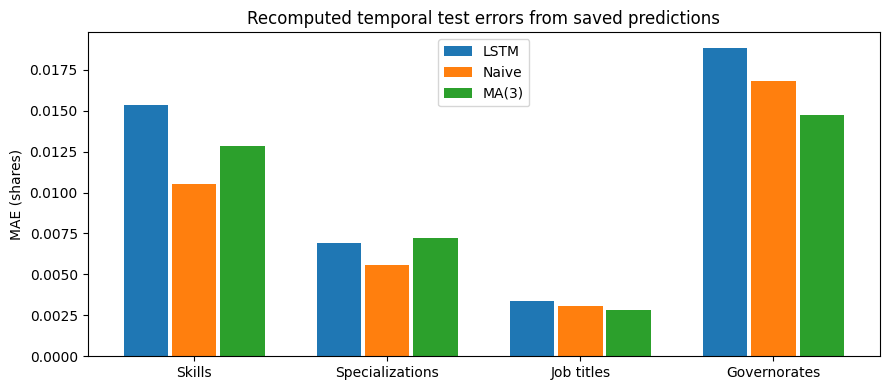

In [10]:
fams=list(forecast_recomputed)
x=np.arange(len(fams)); fig,ax=plt.subplots(figsize=(9,4))
for i,(col,lab) in enumerate([('lstm','LSTM'),('naive','Naive'),('moving_avg_3','MA(3)')]):
    ax.bar(x+(i-1)*.25,[forecast_recomputed[f][col]['mae'] for f in fams],.23,label=lab)
ax.set_xticks(x, ['Skills','Specializations','Job titles','Governorates'])
ax.set_ylabel('MAE (shares)');ax.set_title('Recomputed temporal test errors from saved predictions');ax.legend()
fig.tight_layout();display(fig);plt.close(fig)

## 9. حالة Gold: هل توجد مراجعة بشرية مستقلة؟

In [11]:
gold_status=REPORTS_DIR/'evaluation'/'human_gold_status.json'
if gold_status.is_file():
    g=json.loads(gold_status.read_text(encoding='utf-8'))
    print(json.dumps(g,ensure_ascii=False,indent=2))
else:
    print('لم يُعثر على تقرير Gold')
print('لا يمكن إنتاج Accuracy/F1 على Gold من ملفات التوسيم الفارغة أو silver labels. هذه المرحلة بانتظار توصيف بشري موثق.')

{
  "label_quality": "HUMAN_GOLD_ONLY",
  "annotation_integrity": {
    "classification_pending": 246,
    "classification_verified": 0,
    "ner_pending": 100,
    "ner_verified": 0,
    "errors": [],
    "ready_for_independent_gold_eval": false
  },
  "independent_gold": "Pre-existing split TEST, checked non-overlap against train/validation IDs and canonical groups",
  "status": "BLOCKED_PENDING_HUMAN_ANNOTATION"
}
لا يمكن إنتاج Accuracy/F1 على Gold من ملفات التوسيم الفارغة أو silver labels. هذه المرحلة بانتظار توصيف بشري موثق.


## 10. اختبارات آلية حقيقية لمكونات المشروع (مجموعة محددة مع توثيق نطاقها)

In [12]:
import subprocess
cases=[
 'tests/test_repair_preflight.py::test_word_chunking_no_tokenizer',
 'tests/test_repair_preflight.py::test_repair_invalid_bio',
 'tests/test_repair_preflight.py::test_no_fake_model_fallback',
 'tests/test_offline_integration.py::test_neural_model_load_and_infer_real_checkpoint',
 'tests/test_offline_integration.py::test_market_core_functionality_real_dataset',
 'tests/test_offline_integration.py::test_lstm_saved_weights_reproduce_test_predictions',
 'tests/test_offline_integration.py::test_model_reports_identify_silver_automatic_ground_truth',
]
env=os.environ.copy();env.update({'PYTEST_DISABLE_PLUGIN_AUTOLOAD':'1','OMP_NUM_THREADS':'2','OPENBLAS_NUM_THREADS':'2'})
try:
    runner=subprocess.run([sys.executable,'-m','pytest','-q',*cases,'-p','no:cacheprovider'],
                          cwd=PROJ, env=env, capture_output=True,text=True,timeout=75)
    print(runner.stdout[-2000:]); print(runner.stderr[-500:]);print('RETURN CODE:',runner.returncode)
    if runner.returncode: print('ATTENTION: failed tests, inspect above.')
except subprocess.TimeoutExpired as ex:
    print('TIMEOUT: اختبارات جزئية لم تنته خلال 75 ثانية:',ex)
print('لا تعني هذه المجموعة المحددة أن كل وظائف Streamlit أو جميع اختبارات المشروع نجحت.')

.......                                                                  [100%]
7 passed in 7.35s


RETURN CODE: 0
لا تعني هذه المجموعة المحددة أن كل وظائف Streamlit أو جميع اختبارات المشروع نجحت.


## 11. إنشاء تقرير النتائج التلقائي من التقارير الموجودة (لا ينشئ نتائج AraBERT وهمية)

In [13]:
import runpy
# تنفيذ السكربت مباشرة داخل النواة وتسجيل مخرجاته الفعلية
runpy.run_path(str(PROJ/'scripts'/'build_results_section.py'),run_name='__main__')
res_path=PROJ/'docs'/'RESULTS.md'
if res_path.exists():
    report=res_path.read_text(encoding='utf8')
    print('Results markdown length:',len(report),'characters')
    display(Markdown(report[:3000]+ ('\n\n… (عرض مقتطع؛ الملف الكامل داخل مجلد المشروع)' if len(report)>3000 else '')))
else: print('No results file generated')

✔ /mnt/data/lmi_nb_execution/LMI_PROJECT/docs/RESULTS.md
Results markdown length: 1958 characters


# النتائج

_مولَّد تلقائياً من `reports/` في 2026-11-06T17:28:21 — لا أرقام مكتوبة يدوياً._

كل النتائج على تقسيم **test** المستقل (لم يُستخدم في التدريب أو اختيار النموذج). الوسوم silver (قواعد)، لذا المقاييس تقيس الاتفاق مع هذه الوسوم ما لم يُذكر Gold.

### تدقيق البيانات
الحكم: **WARN** — {'FAIL': 0, 'WARN': 14, 'PASS': 51}

### تصنيف نوع الفرصة
| النموذج | Accuracy | Macro-P | Macro-R | Macro-F1 | Weighted-F1 |
|---|---|---|---|---|---|
| tfidf_logreg (C=3) | 0.9852 | 0.9304 | 0.8442 | 0.8747 | 0.9849 |
| tfidf_linearsvc (C=1) | 0.9873 | 0.9701 | 0.8068 | 0.8626 | 0.9866 |

### تصنيف النطاق الجغرافي
| النموذج | Accuracy | Macro-P | Macro-R | Macro-F1 | Weighted-F1 |
|---|---|---|---|---|---|
| tfidf_logreg (C=10) | 0.9282 | 0.8547 | 0.7657 | 0.8014 | 0.9277 |
| tfidf_linearsvc (C=3) | 0.9388 | 0.9013 | 0.7067 | 0.7708 | 0.9360 |

### استخراج الكيانات (NER)
| النموذج | Entity-P | Entity-R | Entity-F1 | Macro Entity-F1 |
|---|---|---|---|---|
| CRF | 0.8355 | 0.8111 | 0.8231 | 0.8170 |

CRF لكل كيان:

| الكيان | P | R | F1 | Support |
|---|---|---|---|---|
| DEADLINE | 0.9055 | 0.8767 | 0.8909 | 503 |
| DEGREE | 0.8307 | 0.8618 | 0.8460 | 615 |
| EXPERIENCE | 0.8096 | 0.8296 | 0.8195 | 487 |
| JOB_TITLE | 0.9113 | 0.8475 | 0.8783 | 1843 |
| LOCATION | 0.9204 | 0.8677 | 0.8933 | 960 |
| MAJOR | 0.7312 | 0.6258 | 0.6744 | 326 |
| ORGANIZATION | 0.9523 | 0.9311 | 0.9416 | 1350 |
| SALARY | 0.7250 | 0.6259 | 0.6718 | 139 |
| SKILL | 0.7398 | 0.7347 | 0.7372 | 3540 |

### التنبؤ الزمني (LSTM)
| العائلة | دُرّب | السلاسل | LSTM MAE | Naive MAE | MA-3 MAE | LSTM RMSE | الأفضل (MAE) | السبب إن لم يُدرَّب |
|---|---|---|---|---|---|---|---|---|
| skills | نعم | 72 | 0.0153 | 0.0105 | 0.0128 | 0.0287 | Naive |  |
| specializations | نعم | 18 | 0.0069 | 0.0056 | 0.0073 | 0.0102 | Naive |  |
| job_titles | نعم | 7 | 0.0034 | 0.0031 | 0.0028 | 0.0048 | MA-3 |  |
| governorates | نعم | 13 | 0.0188 | 0.0168 | 0.0147 | 0.0317 | MA-3 |  |


## 12. حالة الواجهة وملفات النموذج في هذه البيئة

In [14]:
import compileall
ok=compileall.compile_dir(str(PROJ/'app_dl'), quiet=1, force=False)
print('Streamlit app syntax compilation:', 'PASS' if ok else 'FAIL')
print('Streamlit package available:',importlib.util.find_spec('streamlit') is not None)
print('Browser/E2E check:', 'NOT EXECUTED — لا تتوفر مكتبة Streamlit أو متصفح/نفق Colab في بيئة التنفيذ الحالية')
print('External public URL:', 'NOT GENERATED')

Streamlit app syntax compilation: PASS
Streamlit package available: False
Browser/E2E check: NOT EXECUTED — لا تتوفر مكتبة Streamlit أو متصفح/نفق Colab في بيئة التنفيذ الحالية
External public URL: NOT GENERATED


## 13. خلاصة التنفيذ وما تبقى من الدفتر الأصلي

In [15]:
status={
 'فك المشروع وقراءة البيانات':'EXECUTED',
 'تقييم مصنفي PyTorch على Silver Test':'EXECUTED',
 'تقييم NER Entity-level على Silver Test':'EXECUTED',
 'إعادة حساب MAE من اختبار LSTM المحفوظ':'EXECUTED',
 'اختبارات وحدات مختارة':'EXECUTED (see cell output)',
 'تدريب AraBERT الحقيقي':'NOT EXECUTED: pretrained weights/dependencies unavailable',
 'Gold human evaluation':'NOT EXECUTED: no reviewed Gold labels',
 'تشغيل Streamlit في متصفح':'NOT EXECUTED: streamlit unavailable',
 'ربط Google Drive':'NOT EXECUTED: this execution was outside Colab',
}
for key,value in status.items():print(f'{key}: {value}')
print('\nيحتوي هذا الملف على المخرجات الفعلية أعلاه. لنتائج AraBERT يجب تنفيذ fine-tuning على Colab/بيئة تملك أوزان النموذج ومكتباته.')

فك المشروع وقراءة البيانات: EXECUTED
تقييم مصنفي PyTorch على Silver Test: EXECUTED
تقييم NER Entity-level على Silver Test: EXECUTED
إعادة حساب MAE من اختبار LSTM المحفوظ: EXECUTED
اختبارات وحدات مختارة: EXECUTED (see cell output)
تدريب AraBERT الحقيقي: NOT EXECUTED: pretrained weights/dependencies unavailable
Gold human evaluation: NOT EXECUTED: no reviewed Gold labels
تشغيل Streamlit في متصفح: NOT EXECUTED: streamlit unavailable
ربط Google Drive: NOT EXECUTED: this execution was outside Colab

يحتوي هذا الملف على المخرجات الفعلية أعلاه. لنتائج AraBERT يجب تنفيذ fine-tuning على Colab/بيئة تملك أوزان النموذج ومكتباته.


---
### ملحق: ما الذي يفعله الدفتر الأصلي ولم يُنفذ هنا؟

في دفتر `LMI_Drive_Run.ipynb` الأصلي: `drive.mount()`، فك ZIP في Drive، تثبيت `transformers` و`arabert`، تدريب `src.training.train_classifier` للمهمتين و`src.training.train_ner`، تقييم AraBERT على Test، تشغيل Streamlit بنفق Cloudflare ثم تصدير الأوزان. **لم تُحفظ نتائج افتراضية لهذه الخطوات.**

إذا توافرت بيئة Colab مع الشبكة ومكتبات Transformers وأوزان AraBERT، يمكن تشغيل الدفتر الأصلي وتصدير نسخة بمخرجاته بعد انتهاء التدريب فعلياً. ملف هذه النسخة لا يحوّل نماذج TinyClassifier/TinyNER إلى AraBERT ولا يدعي إكمال التدريب.